# 8. Hyperparameter Tuning and Final Model Selection

Tunes the five classifiers with `GridSearchCV` (5-fold stratified CV, scoring = F1) on the **training set only**, then evaluates each tuned model once on the untouched test set. The final model is chosen by **cross-validated F1**, not by test score.

Uses the same split as notebook 6 (`test_size=0.20`, `random_state=42`, `stratify=y`).

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve)

df = pd.read_csv('../data/customer_features.csv')
feature_cols = ['Recency','Frequency','Monetary','AverageOrderValue','ProductDiversity','AvgItemsPerOrder']
log_cols = feature_cols[1:]
X, y = df[feature_cols], df['RepeatPurchase_90D']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(4224, 6) (1057, 6)


In [2]:
def make_preprocessor():
    return Pipeline([
        ('feature_transform', ColumnTransformer([('log', FunctionTransformer(np.log1p), log_cols)], remainder='passthrough')),
        ('scaler', StandardScaler())])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search_space = {
 'Logistic Regression': (Pipeline([('p', make_preprocessor()), ('c', LogisticRegression(max_iter=2000, random_state=42))]),
     {'c__C':[0.01,0.1,1,10,100], 'c__penalty':['l2'], 'c__class_weight':[None,'balanced']}),
 'Decision Tree': (DecisionTreeClassifier(random_state=42),
     {'max_depth':[3,5,7,10,None], 'min_samples_leaf':[1,5,10,20], 'criterion':['gini','entropy']}),
 'Random Forest': (RandomForestClassifier(random_state=42, n_jobs=-1),
     {'n_estimators':[200,400], 'max_depth':[5,10,None], 'min_samples_leaf':[1,3,5], 'max_features':['sqrt',0.5]}),
 'KNN': (Pipeline([('p', make_preprocessor()), ('c', KNeighborsClassifier())]),
     {'c__n_neighbors':[5,11,15,21,31], 'c__weights':['uniform','distance']}),
 'SVM': (Pipeline([('p', make_preprocessor()), ('c', SVC(kernel='rbf', probability=True, random_state=42))]),
     {'c__C':[0.1,1,10], 'c__gamma':['scale',0.01,0.1]}),
}

In [3]:
rows, best_models = [], {}
for name, (model, grid) in search_space.items():
    gs = GridSearchCV(model, grid, cv=cv, scoring='f1', n_jobs=-1).fit(X_train, y_train)
    best = gs.best_estimator_; best_models[name] = best
    pred, proba = best.predict(X_test), best.predict_proba(X_test)[:, 1]
    rows.append({'Model': name, 'Best parameters': gs.best_params_, 'CV F1 (train)': gs.best_score_,
                 'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred),
                 'Recall': recall_score(y_test, pred), 'F1': f1_score(y_test, pred), 'ROC-AUC': roc_auc_score(y_test, proba)})
results = pd.DataFrame(rows).sort_values('CV F1 (train)', ascending=False).reset_index(drop=True)
results

,Model,Best parameters,CV F1 (train),Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,"{'c__C': 1, 'c__class_weight': 'balanced', 'c_...",0.692017,0.726585,0.667327,0.735808,0.699896,0.807576
1,SVM,"{'c__C': 10, 'c__gamma': 'scale'}",0.673109,0.733207,0.712560,0.644105,0.676606,0.787105
2,KNN,"{'c__n_neighbors': 31, 'c__weights': 'uniform'}",0.670343,0.720908,0.689095,0.648472,0.668166,0.790149
3,Random Forest,"{'max_depth': 5, 'max_features': 'sqrt', 'min_...",0.668699,0.727531,0.703349,0.641921,0.671233,0.805939
4,Decision Tree,"{'criterion': 'gini', 'max_depth': 5, 'min_sam...",0.652824,0.746452,0.732843,0.652838,0.690531,0.796218


## Final model selection
The model with the highest cross-validated F1 is selected. Test scores are reported only once, after selection.

Selected model: Logistic Regression
[[431 168]
 [121 337]]


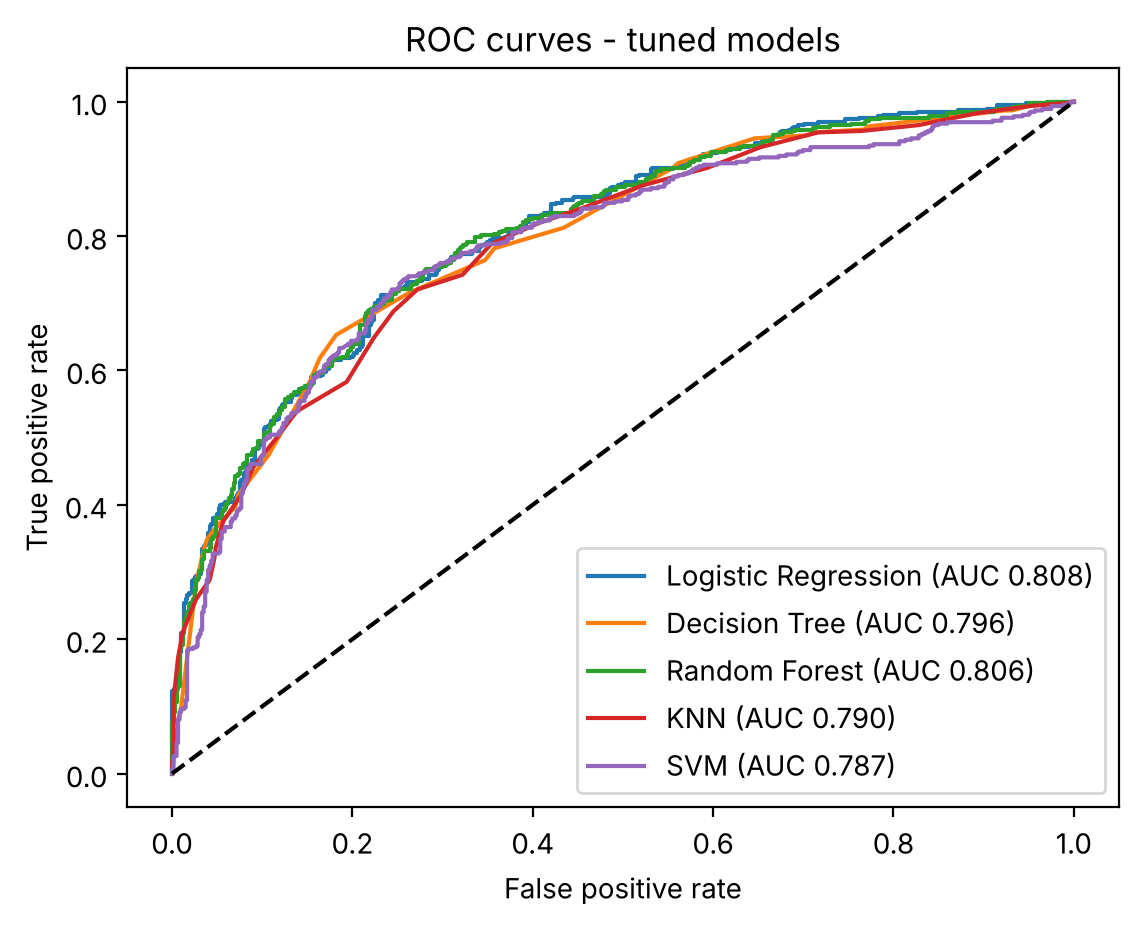

In [4]:
final_name = results.loc[0, 'Model']; final_model = best_models[final_name]
print('Selected model:', final_name)
print(confusion_matrix(y_test, final_model.predict(X_test)))

for name, m in best_models.items():
    f, t, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    plt.plot(f, t, label=f"{name} (AUC {roc_auc_score(y_test, m.predict_proba(X_test)[:,1]):.3f})")
plt.plot([0,1],[0,1],'k--'); plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('ROC curves - tuned models'); plt.legend(); plt.show()

In [5]:
# Logistic Regression coefficients with the CORRECT feature order.
# ColumnTransformer outputs the log-transformed columns first and the passthrough column (Recency) last.
lr = best_models['Logistic Regression'].named_steps['c']
ordered_features = log_cols + ['Recency']
pd.Series(lr.coef_[0], index=ordered_features).sort_values()

Monetary            -0.856539
Recency             -0.710980
AvgItemsPerOrder     0.115717
ProductDiversity     0.319258
AverageOrderValue    0.476510
Frequency            1.119180
dtype: float64

In [6]:
import joblib, os
os.makedirs('../models', exist_ok=True)
joblib.dump(final_model, '../models/final_tuned_model.pkl')

['../models/final_tuned_model.pkl']